# Churn operadora

In [1]:
!pip install mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 68.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 72.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 68.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 147.8/147.8 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 197.1/197.1 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.0/77.0 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.2/131.2 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 828.0/828.0 kB 41.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.3/207.3 kB 15.6 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import re
from datetime import datetime
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import LinearSVC, SVC
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, accuracy_score, auc, confusion_matrix, f1_score, precision_score, recall_score, roc_curve
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import stats
import plotly.express as px
import plotly.graph_objects as go
import mlflow
from bs4 import BeautifulSoup

sns.set()
get_ipython().run_line_magic('matplotlib', 'inline')

## Cargar los datasets y construir un único tablón analítico con todas las variables

In [3]:
dic_clientes = pd.read_csv("clientes_diciembre.csv", sep = "|", parse_dates = ["antiguedad"])
dic_consumos = pd.read_csv("consumos_diciembre.csv", sep = "|")
dic_fin = pd.read_csv("financiacion_diciembre.csv", sep = "|")
dic_prod = pd.read_csv("productos_diciembre.csv", sep = "|")

In [4]:
print('Tamaño de tabla de consumos diciembre:',dic_consumos.shape[0])
print('Tamaño de tabla de clientes diciembre:',dic_clientes.shape[0])
print('Tamaño de tabla de financiación diciembre:',dic_fin.shape[0])
print('Tamaño de tabla de productos diciembre:',dic_prod.shape[0])

Tamaño de tabla de consumos diciembre: 95467
Tamaño de tabla de clientes diciembre: 95467
Tamaño de tabla de financiación diciembre: 24198
Tamaño de tabla de productos diciembre: 95467


In [5]:
print('Clientes en tabla clientes\n', dic_clientes['id'].duplicated().value_counts())
print('Clientes en tabla consumos\n',dic_consumos['id'].duplicated().value_counts())
print('Clientes en tabla productos\n',dic_prod['id'].duplicated().value_counts())
print('Clientes en tabla financiación\n',dic_fin['id'].duplicated().value_counts())

Clientes en tabla clientes
 id
False    95466
True         1
Name: count, dtype: int64
Clientes en tabla consumos
 id
False    95467
Name: count, dtype: int64
Clientes en tabla productos
 id
False    95467
Name: count, dtype: int64
Clientes en tabla financiación
 id
False    24198
Name: count, dtype: int64


In [6]:
dic_clientes['id'][dic_clientes['id'].duplicated()]

,id
95460,99993


In [7]:
dic_clientes[dic_clientes['id']==99993]

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia
95459,99993,58,375.65842,2016-06-09 21:39:00,Santa Cruz de Tenerife,5,NaN,NaN
95460,99993,58,375.65842,2016-06-09 21:39:00,Santa Cruz de Tenerife,5,NaN,NaN


In [8]:
dic_clientes.drop(95460, axis=0, inplace=True)

In [9]:
print('Clientes en tabla financiacion\n', dic_clientes['id'].isin(dic_fin['id']).value_counts())
print('Clientes en tabla consumos\n',dic_clientes['id'].isin(dic_consumos['id']).value_counts())
print('Clientes en tabla productos\n',dic_clientes['id'].isin(dic_prod['id']).value_counts())

Clientes en tabla financiacion
 id
False    71269
True     24197
Name: count, dtype: int64
Clientes en tabla consumos
 id
True    95466
Name: count, dtype: int64
Clientes en tabla productos
 id
True    95466
Name: count, dtype: int64


In [10]:
dic_cl_con = pd.merge(dic_clientes, dic_consumos, on = "id", how = "left")
dic_cl_con_f = pd.merge(dic_cl_con, dic_fin, on= "id", how = "left")
dic_full = pd.merge(dic_cl_con_f, dic_prod, on = "id", how = "left")

In [11]:
dic_full.head()

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia,num_llamad_ent,num_llamad_sal,mb_datos,seg_llamad_ent,seg_llamad_sal,financiacion,imp_financ,descuentos,conexion,vel_conexion,TV
0,1,63,216.028109,2018-11-23 08:48:00,La Rioja,5,NaN,NaN,110,79,10897,12806,13751,NaN,NaN,NaN,FIBRA,50MB,tv-futbol
1,2,84,255.830842,2017-08-22 03:19:00,Vizcaya,3,NaN,NaN,189,89,18657,6499,10862,NaN,NaN,SI,FIBRA,600MB,tv-futbol
2,3,66,135.768153,2001-12-27 13:50:00,Albacete,4,NaN,NaN,129,30,15511,17013,16743,NaN,NaN,SI,ADSL,35MB,tv-futbol
3,4,69,255.658527,2015-08-08 10:53:00,Lugo,4,NaN,NaN,51,52,12670,3393,6771,NaN,NaN,NaN,FIBRA,200MB,tv-familiar
4,5,30,22.302845,1997-08-29 02:19:00,Tarragona,2,2.0,NaN,183,3,23756,18436,4485,NaN,NaN,NaN,ADSL,10MB,tv-futbol


In [12]:
dic_full.shape

(95466, 19)

In [13]:
en_clientes = pd.read_csv("clientes_enero.csv", sep = "|", parse_dates = ["antiguedad"])
en_consumos = pd.read_csv("consumos_enero.csv", sep = "|")
en_fin = pd.read_csv("financiacion_enero.csv", sep = "|")
en_prod = pd.read_csv("productos_enero.csv", sep = "|")

In [14]:
print('Clientes en tabla clientes\n', en_clientes['id'].duplicated().value_counts())
print('Clientes en tabla consumos\n',en_consumos['id'].duplicated().value_counts())
print('Clientes en tabla productos\n',en_prod['id'].duplicated().value_counts())
print('Clientes en tabla financiación\n',en_fin['id'].duplicated().value_counts())

Clientes en tabla clientes
 id
False    92710
Name: count, dtype: int64
Clientes en tabla consumos
 id
False    92711
Name: count, dtype: int64
Clientes en tabla productos
 id
False    92711
Name: count, dtype: int64
Clientes en tabla financiación
 id
False    25332
Name: count, dtype: int64


In [15]:
en_clientes['id'][en_clientes['id'].duplicated()]

,id


In [16]:
en_clientes[en_clientes['id']==75418]

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia
69931,75418,63,302.943455,1995-12-07 18:36:00,Santa Cruz de Tenerife,5,NaN,NaN


In [17]:
en_clientes.drop(69931, axis=0, inplace=True)

In [18]:
print('Tamaño de tabla de consumos enero:',en_consumos.shape[0])
print('Tamaño de tabla de clientes enero:',en_clientes.shape[0])
print('Tamaño de tabla de financiación enero:',en_fin.shape[0])
print('Tamaño de tabla de productos enero:',en_prod.shape[0])

Tamaño de tabla de consumos enero: 92711
Tamaño de tabla de clientes enero: 92709
Tamaño de tabla de financiación enero: 25332
Tamaño de tabla de productos enero: 92711


In [19]:
print('Clientes en tabla financiacion\n', en_clientes['id'].isin(en_fin['id']).value_counts())
print('Clientes en tabla consumos\n',en_clientes['id'].isin(en_consumos['id']).value_counts())
print('Clientes en tabla productos\n',en_clientes['id'].isin(en_prod['id']).value_counts())

Clientes en tabla financiacion
 id
False    67377
True     25332
Name: count, dtype: int64
Clientes en tabla consumos
 id
True    92709
Name: count, dtype: int64
Clientes en tabla productos
 id
True    92709
Name: count, dtype: int64


In [20]:
en_cl_con = pd.merge(en_clientes, en_consumos, on = "id", how = "left")
en_cl_con_f = pd.merge(en_cl_con, en_fin, on = "id", how = "left")
en_full = pd.merge(en_cl_con_f, en_prod, on = "id", how = "left")

In [21]:
## Valores únicos
print('Enero: ',len(en_full['id'].unique()))
print('Diciembre: ',len(dic_full['id'].unique()))

Enero:  92709
Diciembre:  95466


In [22]:
dic_full["mes"] = "dic"
en_full["mes"] = "en"

   - Se observa que en enero hubo una disminución de 3000 clientes aproximadamente. Por tanto, la empresa perdió más clientes de los que ganó.
        - __7087 clientes abandonaron la empresa.__

In [23]:
len(dic_full) - dic_full.id.isin(en_full.id).sum()

np.int64(7087)

   - Creación de la variable target. Se buscan los "id" de enero que coinciden con los de diciembre, asignando 0 si son idénticos o 1 si no lo son.

In [24]:
churn = pd.DataFrame()
churn['churn'] = np.where(dic_full.id.isin(en_full.id) == True, 0, 1)
churn['id'] =dic_full['id']

In [25]:
####  Antes de concatenar las cosechas, voy a transformar la variable antigüedad
dic_full['duracion'] = (datetime(2019,12,31) - dic_full["antiguedad"])
en_full['duracion'] = (datetime(2020,1,31) - en_full["antiguedad"])

In [26]:
## Concatenamos las dos cosechas y normalizamos todas las variables

data = pd.concat([dic_full, en_full], sort = False, ignore_index=True)
data.columns= data.columns.str.lower()
data.head()

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia,num_llamad_ent,num_llamad_sal,...,seg_llamad_ent,seg_llamad_sal,financiacion,imp_financ,descuentos,conexion,vel_conexion,tv,mes,duracion
0,1,63,216.028109,2018-11-23 08:48:00,La Rioja,5,NaN,NaN,110,79,...,12806,13751,NaN,NaN,NaN,FIBRA,50MB,tv-futbol,dic,402 days 15:12:00
1,2,84,255.830842,2017-08-22 03:19:00,Vizcaya,3,NaN,NaN,189,89,...,6499,10862,NaN,NaN,SI,FIBRA,600MB,tv-futbol,dic,860 days 20:41:00
2,3,66,135.768153,2001-12-27 13:50:00,Albacete,4,NaN,NaN,129,30,...,17013,16743,NaN,NaN,SI,ADSL,35MB,tv-futbol,dic,6577 days 10:10:00
3,4,69,255.658527,2015-08-08 10:53:00,Lugo,4,NaN,NaN,51,52,...,3393,6771,NaN,NaN,NaN,FIBRA,200MB,tv-familiar,dic,1605 days 13:07:00
4,5,30,22.302845,1997-08-29 02:19:00,Tarragona,2,2.0,NaN,183,3,...,18436,4485,NaN,NaN,NaN,ADSL,10MB,tv-futbol,dic,8158 days 21:41:00


In [27]:
# Transformación de la variable antigüedad a días, horas... Esta parte podría hacerse en la parte de FE
data["duracion"] = data.duracion.apply(lambda x: int(x.days))

# Month:
data["month"] = data.antiguedad.apply(lambda x: x.strftime("%B"))

# Lo mismo con día de la semana.
data["dia"] = data.antiguedad.apply(lambda x: x.strftime("%A"))

# Recoger la info de la hora.
data["hora"] = data.antiguedad.apply(lambda x: int(x.hour))

# Categórica para poder tener interpretabilidad.
data["hora_bin"] = pd.cut(data["hora"], bins = [-1,6,12,18,23], labels = ["Madrugada", "Mañana", "Tarde", "Noche"])

# Se elimina la variable original pues ya está convertida a numérica.
data.drop(columns = "antiguedad", inplace = True)

# Pre procesado y  limpieza de los datos



In [28]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188175 entries, 0 to 188174
Data columns (total 24 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   id              188175 non-null  int64   
 1   edad            188175 non-null  int64   
 2   facturacion     188175 non-null  float64 
 3   provincia       188175 non-null  object  
 4   num_lineas      188175 non-null  int64   
 5   num_dt          7342 non-null    float64 
 6   incidencia      5565 non-null    object  
 7   num_llamad_ent  188175 non-null  int64   
 8   num_llamad_sal  188175 non-null  int64   
 9   mb_datos        188175 non-null  int64   
 10  seg_llamad_ent  188175 non-null  int64   
 11  seg_llamad_sal  188175 non-null  int64   
 12  financiacion    13037 non-null   object  
 13  imp_financ      13037 non-null   float64 
 14  descuentos      39192 non-null   object  
 15  conexion        188173 non-null  object  
 16  vel_conexion    188169 non-null  objec

In [29]:
cat_cols= data.select_dtypes(include=['object','category']).columns
num_cols = data.select_dtypes(exclude=['object','category']).columns

In [30]:
data[cat_cols].describe()

,provincia,incidencia,financiacion,descuentos,conexion,vel_conexion,tv,mes,month,dia,hora_bin
count,188175,5565,13037,39192,188173,188169,188175,188175,188175,188175,188175
unique,50,1,1,1,2,14,3,2,12,7,4
top,Zaragoza,SI,SI,SI,ADSL,200MB,tv-futbol,dic,January,Wednesday,Madrugada
freq,3918,5565,13037,39192,95220,19017,95823,95466,19953,27211,54984


In [31]:
data[num_cols].describe()

,id,edad,facturacion,num_lineas,num_dt,num_llamad_ent,num_llamad_sal,mb_datos,seg_llamad_ent,seg_llamad_sal,imp_financ,duracion,hora
count,188175.000000,188175.000000,188175.000000,188175.000000,7342.000000,188175.000000,188175.000000,188175.000000,188175.000000,188175.000000,13037.000000,188175.000000,188175.000000
mean,49995.408551,50.592023,207.439861,3.559729,2.515800,124.961408,49.942054,12499.893381,9964.880537,9979.309138,22.270776,4483.246239,11.500189
std,28868.003995,19.728832,111.291714,1.090758,1.122498,72.457421,29.163880,7228.744706,5779.610857,5803.465816,10.169640,2687.114879,6.927343
min,1.000000,18.000000,15.000439,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.009999,-1.000000,0.000000
25%,24979.500000,33.000000,111.371633,3.000000,2.000000,62.000000,25.000000,6205.000000,4956.000000,4959.000000,13.444882,2158.000000,6.000000
50%,49984.000000,50.000000,206.927616,4.000000,3.000000,125.000000,50.000000,12496.000000,9959.000000,9980.000000,21.883685,4491.000000,12.000000
75%,75004.500000,68.000000,304.388724,4.000000,4.000000,188.000000,75.000000,18764.000000,14965.000000,14998.000000,31.134052,6807.000000,18.000000
max,100000.000000,85.000000,399.998433,39.000000,4.000000,250.000000,100.000000,25000.000000,20000.000000,20000.000000,39.991954,9160.000000,23.000000


##  Tratamiento de nulos

In [32]:
data.isnull().sum()

,0
id,0
edad,0
facturacion,0
provincia,0
num_lineas,0
num_dt,180833
incidencia,182610
num_llamad_ent,0
num_llamad_sal,0
mb_datos,0


In [33]:
## Las variables incidencia, financiación, descuentos cuando están a nulo significa que es NO (0)

var_no = ['incidencia','financiacion','descuentos']

for i in var_no:
    data[i].fillna('NO',inplace=True)

/tmp/ipykernel_554/1924785688.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data[i].fillna('NO',inplace=True)


In [34]:
## Las variables num_dt, imp_financ cuando están a nulo significa que es el valor es 0.
var_cero = ['num_dt','imp_financ']

for i in var_cero:
    data[i].fillna(0,inplace=True)

/tmp/ipykernel_554/509841037.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data[i].fillna(0,inplace=True)


In [35]:
data.isnull().sum()

,0
id,0
edad,0
facturacion,0
provincia,0
num_lineas,0
num_dt,0
incidencia,0
num_llamad_ent,0
num_llamad_sal,0
mb_datos,0


<Axes: xlabel='vel_conexion'>

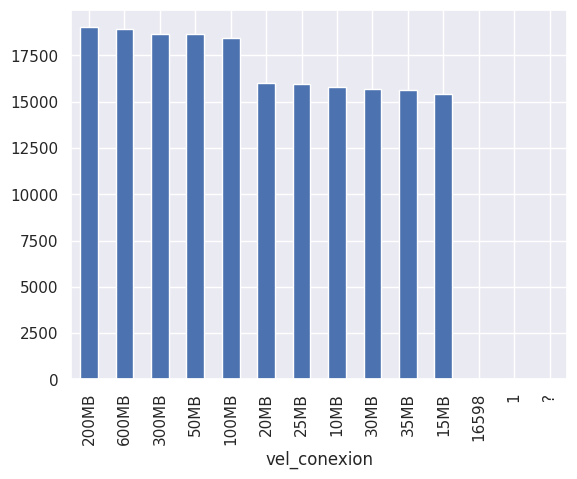

In [36]:
data['vel_conexion'].value_counts().plot(kind='bar')

In [37]:
data.dtypes

,0
id,int64
edad,int64
facturacion,float64
provincia,object
num_lineas,int64
num_dt,float64
incidencia,object
num_llamad_ent,int64
num_llamad_sal,int64
mb_datos,int64


In [38]:
data[data['vel_conexion']=='?']

,id,edad,facturacion,provincia,num_lineas,num_dt,incidencia,num_llamad_ent,num_llamad_sal,mb_datos,...,descuentos,conexion,vel_conexion,tv,mes,duracion,month,dia,hora,hora_bin
70528,73889,69,118.515385,Castellón,2,0.0,NO,74,99,12169,...,NO,FIBRA,?,tv-familiar,dic,6108,April,Thursday,19,Noche


In [39]:
data[data['vel_conexion']=='1']

,id,edad,facturacion,provincia,num_lineas,num_dt,incidencia,num_llamad_ent,num_llamad_sal,mb_datos,...,descuentos,conexion,vel_conexion,tv,mes,duracion,month,dia,hora,hora_bin
70426,73779,26,209.565464,Pontevedra,5,1.0,NO,82,29,9667,...,NO,ADSL,1,tv-futbol,dic,7422,September,Saturday,1,Madrugada


In [40]:
data[data['vel_conexion']=='16598']

,id,edad,facturacion,provincia,num_lineas,num_dt,incidencia,num_llamad_ent,num_llamad_sal,mb_datos,...,descuentos,conexion,vel_conexion,tv,mes,duracion,month,dia,hora,hora_bin
12,13,55,209.36555,Huelva,3,0.0,NO,118,13,18030,...,NO,FIBRA,16598,tv-familiar,dic,137,August,Thursday,23,Noche


In [41]:
adsl = data.query('conexion == "ADSL"')
adsl.groupby('vel_conexion')['conexion'].count().sort_values(ascending=False)

,conexion
vel_conexion,
20MB,15995
25MB,15952
10MB,15776
30MB,15708
35MB,15619
15MB,15436
300MB,164
600MB,158
50MB,145


In [42]:
# Vemos que dentro de las conexiones adsl, la velocidad de conexión más repetida es la de 20 MB
data['vel_conexion'] = data['vel_conexion'].replace('1', '20MB')

In [43]:
fibra = data.query('conexion == "FIBRA"')
fibra.groupby('vel_conexion')['conexion'].count().sort_values(ascending=False)

,conexion
vel_conexion,
200MB,18881
600MB,18763
300MB,18508
50MB,18495
100MB,18301
16598,1
?,1


In [44]:
# Vemos que dentro de las conexiones fibra, la velocidad de conexión más repetida es la de 200 MB
data['vel_conexion'] = data['vel_conexion'].replace('?', '200MB')
data['vel_conexion'] = data['vel_conexion'].replace('16598', '200MB')

In [45]:
## Faltan por rellenar unos pocos nulos en la variable conexión y en la variable vel_conexion

print(data.conexion.unique())

print(data.conexion.value_counts())

## La probabilidad de rellenar el valor con ADSL o FIBRA es prácticamente el mismo. En este caso, podríamos rellenarlo con la moda ( ADSL ) o incluso eliminar las dos líneas

data['conexion'].fillna('ADSL',inplace=True)

print(data.vel_conexion.unique())

print(data.vel_conexion.value_counts())

## En el caso de la velocidad, rellenaremos con el valor 200MB (moda). En este caso, se podría haber rellenado también de varias maneras. Normalmente en estos casos, tenemos alguna información más de negocio (velocidad más probable...)

data['vel_conexion'].fillna('200MB',inplace=True)

## Vemos también 3 valores que trataremos después

['FIBRA' 'ADSL' nan]
conexion
ADSL     95220
FIBRA    92953
Name: count, dtype: int64
['50MB' '600MB' '35MB' '200MB' '10MB' '25MB' '30MB' '100MB' '20MB' '300MB'
 '15MB' nan]
vel_conexion
200MB    19019
600MB    18921
300MB    18672
50MB     18640
100MB    18429
20MB     15996
25MB     15952
10MB     15776
30MB     15709
35MB     15619
15MB     15436
Name: count, dtype: int64


/tmp/ipykernel_554/2074076594.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['conexion'].fillna('ADSL',inplace=True)
/tmp/ipykernel_554/2074076594.py:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using

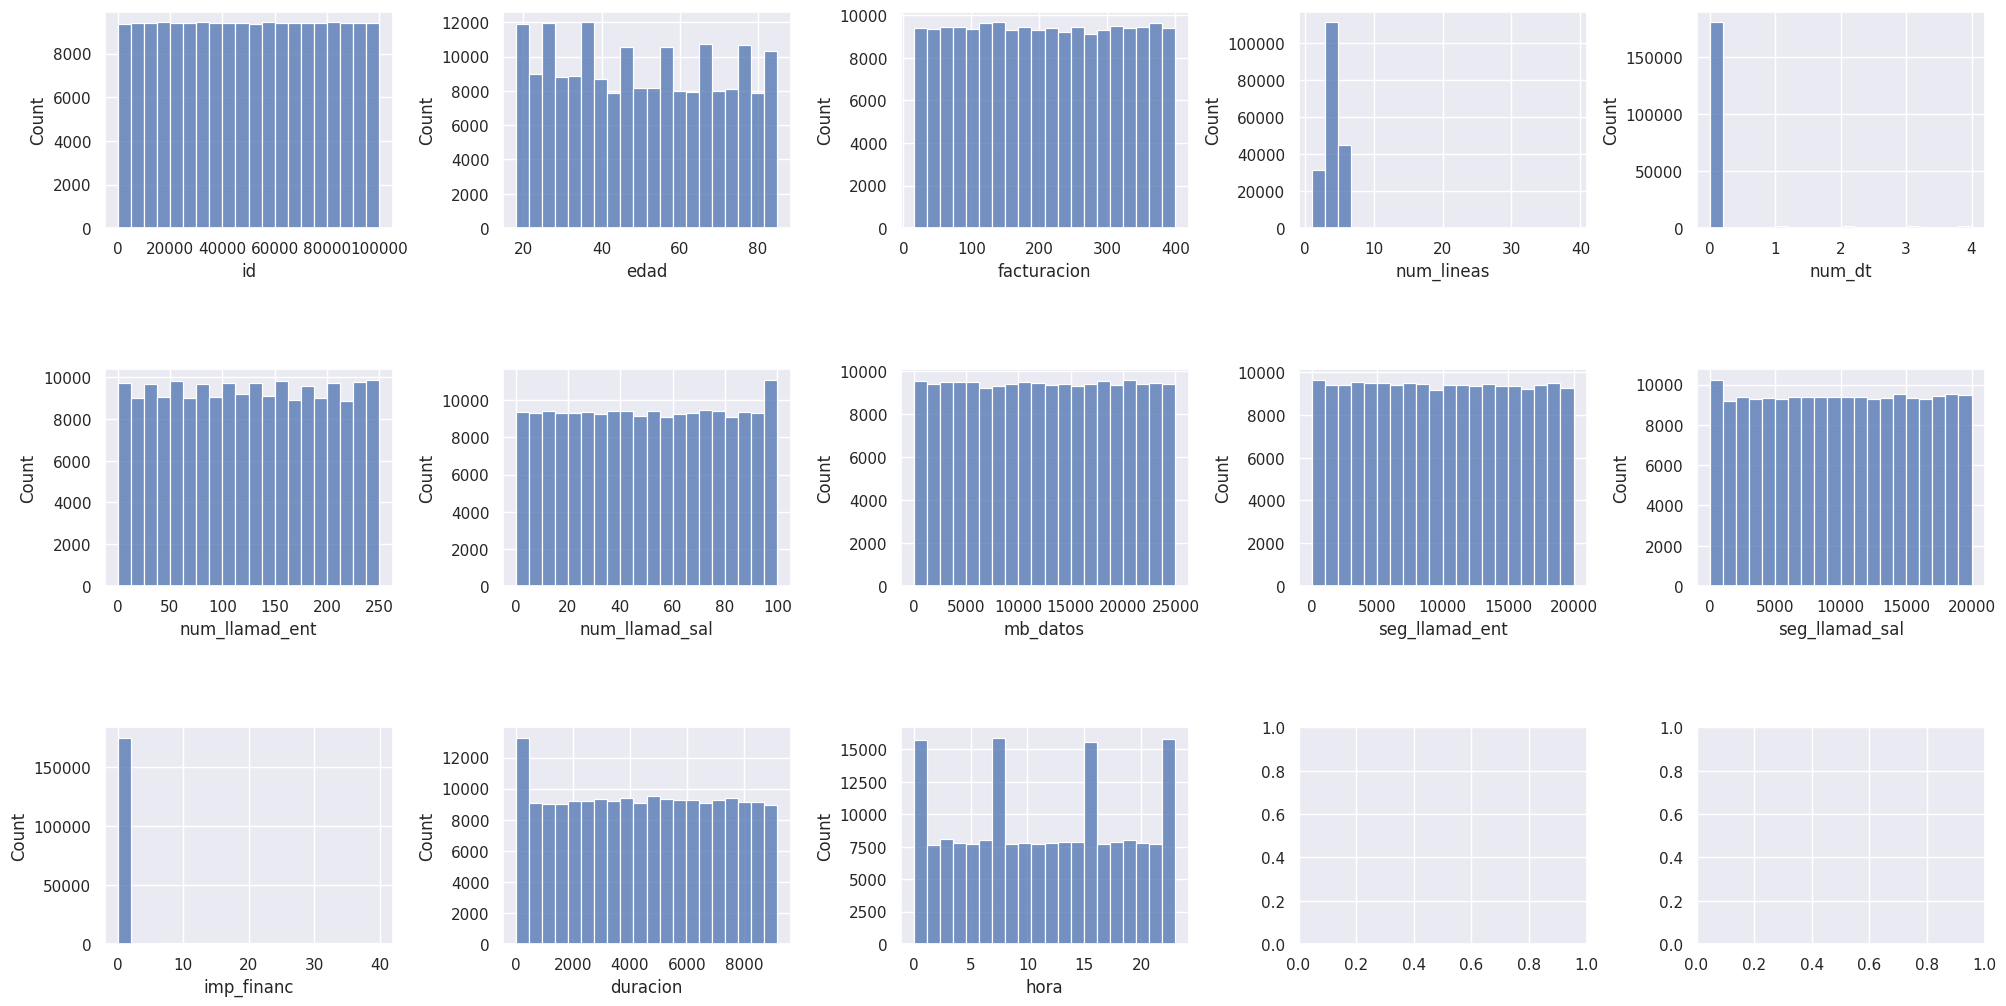

In [46]:
## Variables numéricas
def plot_distributions(df):
    fig, axs = plt.subplots(ncols=5, nrows=3, figsize=(20, 10))
    axs = axs.flatten()
    index = 0
    for k, v in df.items():
        if k == 'permanencia':
            sns.countplot(v, ax=axs[index])
        else:
            sns.histplot(v, bins=20, ax=axs[index])
        index += 1
    plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.0)
    plt.show()

plot_distributions(data.select_dtypes(include=[np.number]))

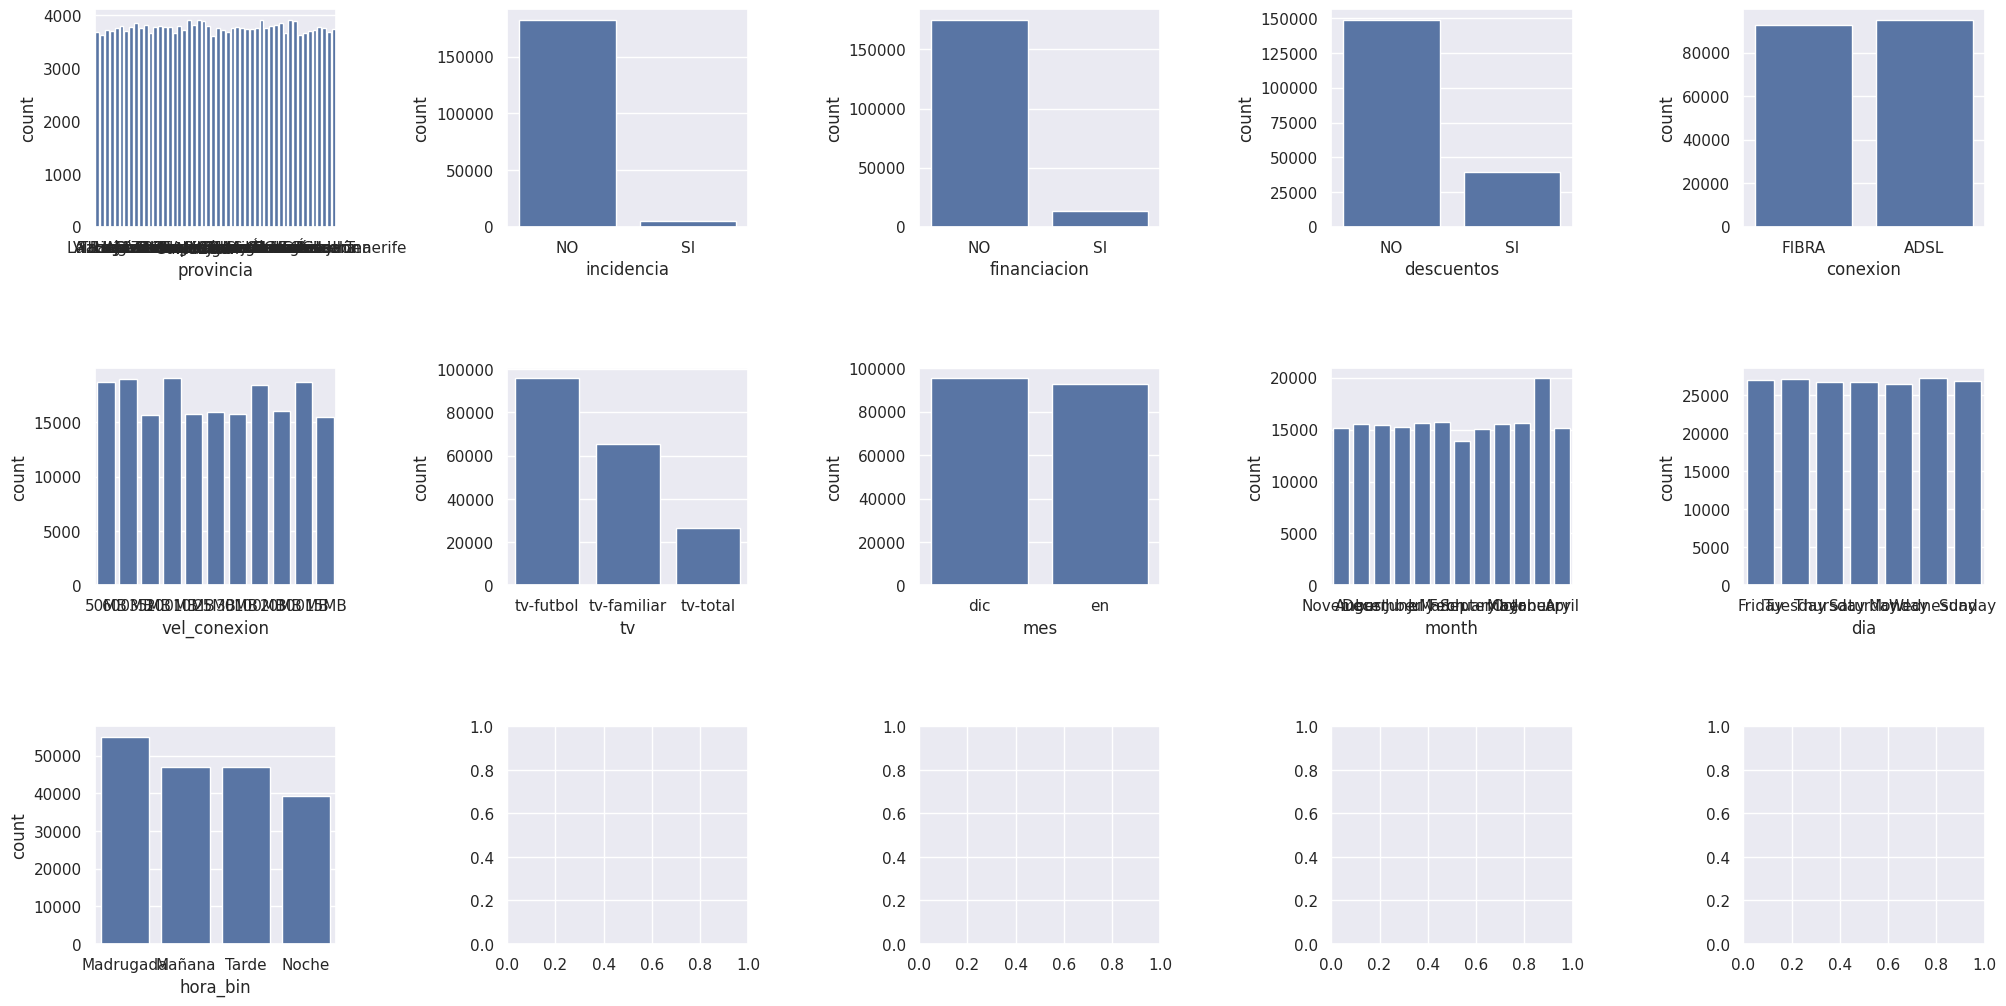

In [47]:
# Variables categóricas
fig, axs = plt.subplots(ncols=5, nrows=3, figsize=(20, 10))
axs = axs.flatten() #

index = 0
for k,v in data[cat_cols].items():
    sns.countplot(data=data, x=v, ax=axs[index])
    index += 1

plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.0)

## Transformación variables a numéricas

In [48]:
data.dtypes

,0
id,int64
edad,int64
facturacion,float64
provincia,object
num_lineas,int64
num_dt,float64
incidencia,object
num_llamad_ent,int64
num_llamad_sal,int64
mb_datos,int64


In [49]:
variables_dummies = ['conexion','tv']
variables_binarias = ['financiacion','descuentos','incidencia']

In [50]:
for k in variables_dummies:
    dummies = pd.get_dummies(data[k],prefix=k)
    data = pd.concat([data, dummies], axis=1)
    data.drop(k, axis=1, inplace=True)

In [51]:
for j in variables_binarias:
    data[j] = [1 if x == 'SI' else 0 for x in data[j]]

In [52]:
data["vel_conexion"] = data.vel_conexion.apply(lambda x: int(re.sub("MB", "", x)))
data.vel_conexion.head()

,vel_conexion
0,50
1,600
2,35
3,200
4,10


In [53]:
## Variables nuevas

data.month.replace(('January','February','March','April','May','June','July','August','September','October','November','December'),
                      (1,2,3,4,5,6,7,8,9,10,11,12),inplace=True)

data.dia.replace(('Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'),
                      (1,2,3,4,5,6,7),inplace=True)

data.hora_bin.replace(('Madrugada','Mañana','Tarde','Noche'),
                      (1,2,3,4),inplace=True)

data.hora_bin = data.hora_bin.astype(int)

/tmp/ipykernel_554/370682244.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data.month.replace(('January','February','March','April','May','June','July','August','September','October','November','December'),
/tmp/ipykernel_554/370682244.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data.m

In [120]:
url = "https://es.wikipedia.org/wiki/Provincia_(Espa%C3%B1a)"

headers = {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) pandas-read-html/1.0"}
html = requests.get(url, headers=headers, timeout=30).text


In [133]:
df_list = pd.read_html(html,flavor="lxml")
ccaa = df_list[2][['Provincia', 'Comunidad autónoma']]
ccaa.columns =ccaa.columns.str.lower()
ccaa = ccaa.rename(columns = {'comunidad autónoma': 'com_aut', 'Provincia': 'provincia'})

/tmp/ipykernel_554/3472004257.py:1: FutureWarning:

Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.



In [142]:
ccaa.provincia.replace(('Baleares'),('Islas Baleares'), inplace=True)

/tmp/ipykernel_554/1848353814.py:1: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.





In [144]:
data = pd.merge(data,ccaa,how='left',on='provincia')

KeyError: 'provincia'

In [58]:
data.com_aut.value_counts()

,count
com_aut,
Castilla y León,33687
Andalucía,30367
Castilla-La Mancha,18522
Galicia,15085
Cataluña,14900
Comunidad Valenciana,11531
Aragón,11246
País Vasco,11231
Extremadura,7569


In [59]:
data.drop('provincia', axis=1, inplace=True )

In [60]:
len(data.com_aut.unique())

17

In [61]:
data.com_aut.unique()

array(['La Rioja', 'País Vasco', 'Castilla-La Mancha', 'Galicia',
       'Cataluña', 'Andalucía', 'Comunidad\xa0Valenciana',
       'Comunidad de Madrid', 'Canarias', 'Castilla y León', 'Aragón',
       'Navarra', 'Extremadura', 'Principado de Asturias',
       'Islas Baleares', 'Cantabria', 'Región de Murcia'], dtype=object)

In [62]:
data.com_aut.replace(('La Rioja', 'País Vasco', 'Castilla-La Mancha', 'Galicia',
                       'Cataluña', 'Andalucía', 'Comunidad\xa0Valenciana',
                       'Comunidad de Madrid', 'Canarias', 'Castilla y León', 'Aragón',
                       'Navarra', 'Extremadura', 'Principado de Asturias',
                       'Islas Baleares', 'Cantabria', 'Región de Murcia'),
                        (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17),inplace=True)

/tmp/ipykernel_554/407177098.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data.com_aut.replace(('La Rioja', 'País Vasco', 'Castilla-La Mancha', 'Galicia',
/tmp/ipykernel_554/407177098.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data.com_aut.replace(('La Rioja', 'País Vasco', 'Castilla

In [63]:
data.com_aut = data.com_aut.astype(int)

In [64]:
data.dtypes

,0
id,int64
edad,int64
facturacion,float64
num_lineas,int64
num_dt,float64
incidencia,int64
num_llamad_ent,int64
num_llamad_sal,int64
mb_datos,int64
seg_llamad_ent,int64


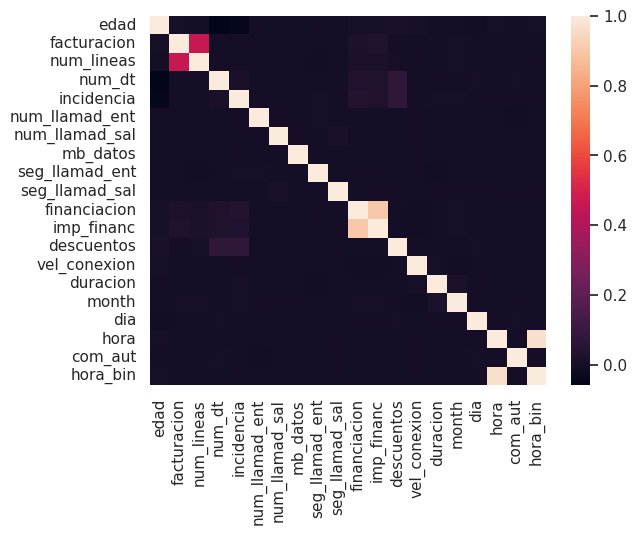

In [65]:
list_correlacion = ['edad', 'facturacion', 'num_lineas', 'num_dt', 'incidencia',
       'num_llamad_ent', 'num_llamad_sal', 'mb_datos', 'seg_llamad_ent',
       'seg_llamad_sal', 'financiacion', 'imp_financ', 'descuentos',
       'vel_conexion','duracion', 'month', 'dia', 'hora','com_aut', 'hora_bin']

df_correlacion = data[list_correlacion]
correlation_mat = df_correlacion.corr()
sns.heatmap(correlation_mat)
plt.show()

## Vemos correlación entre las variables num_lineas y facturacion y seg_llamd_sali y financiación, aunque muy baja

edad


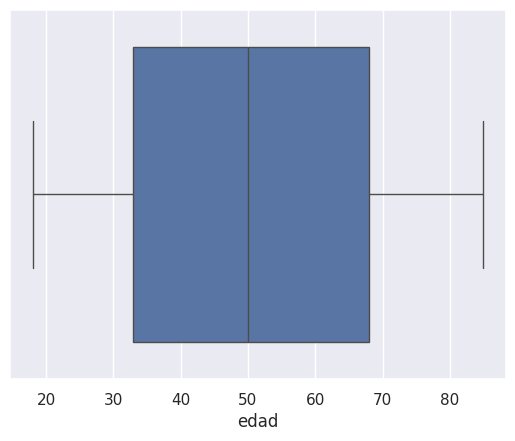

facturacion


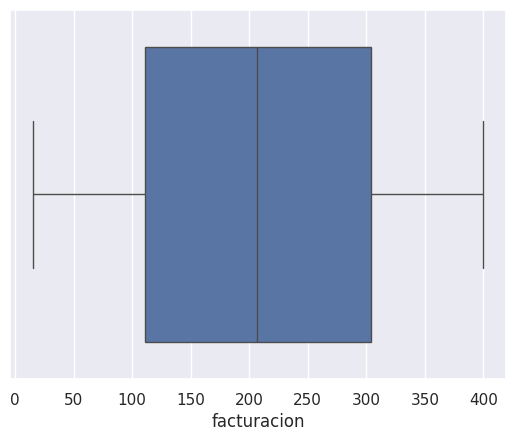

num_lineas


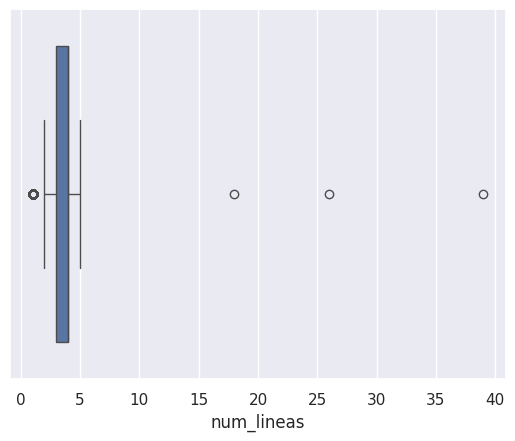

num_dt


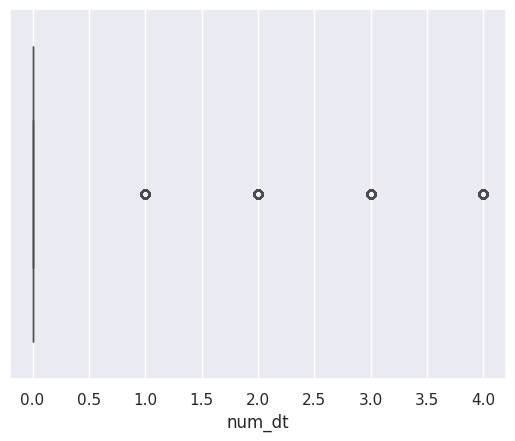

incidencia


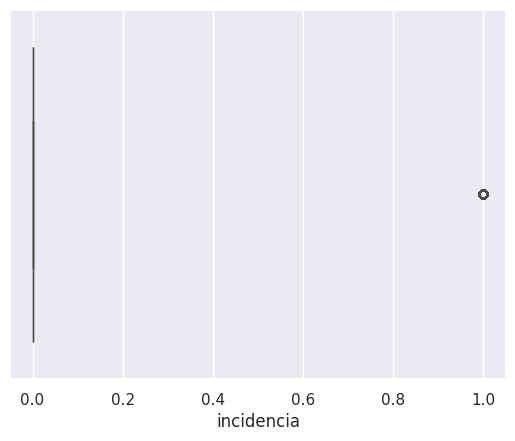

num_llamad_ent


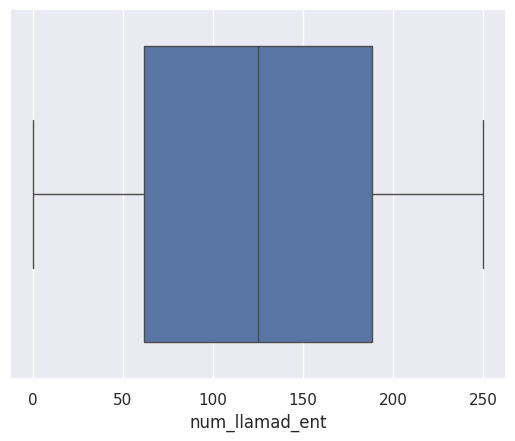

num_llamad_sal


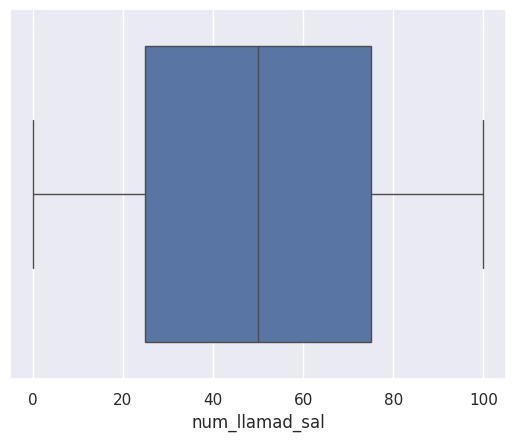

mb_datos


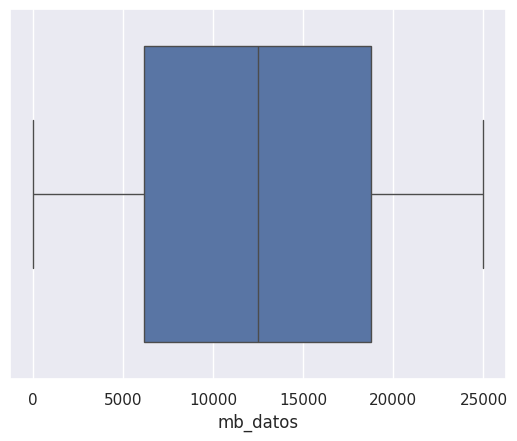

seg_llamad_ent


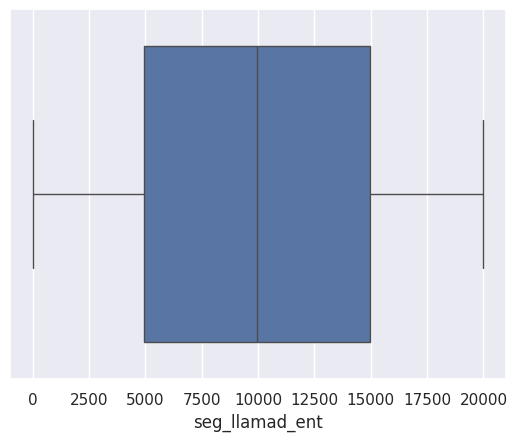

seg_llamad_sal


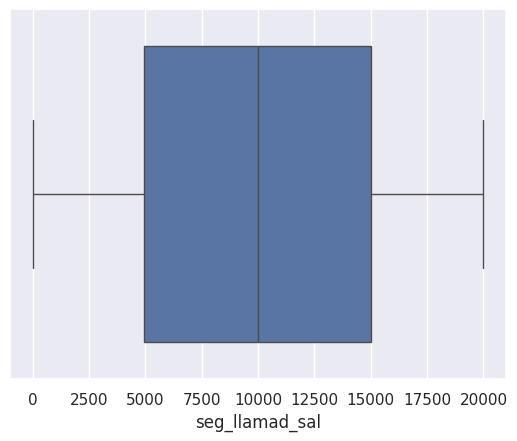

financiacion


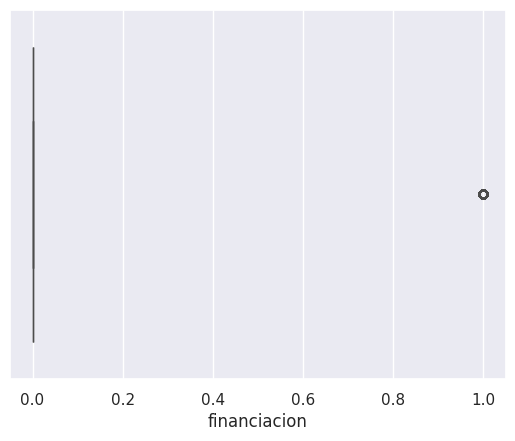

imp_financ


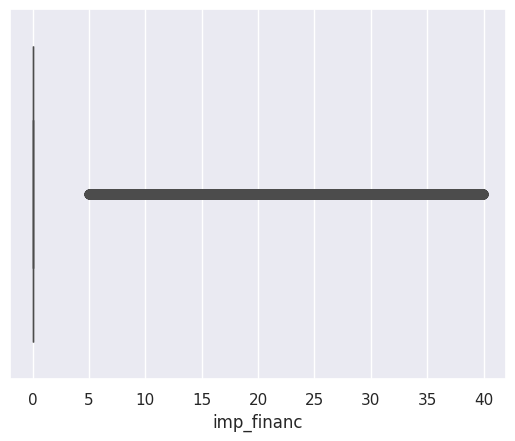

descuentos


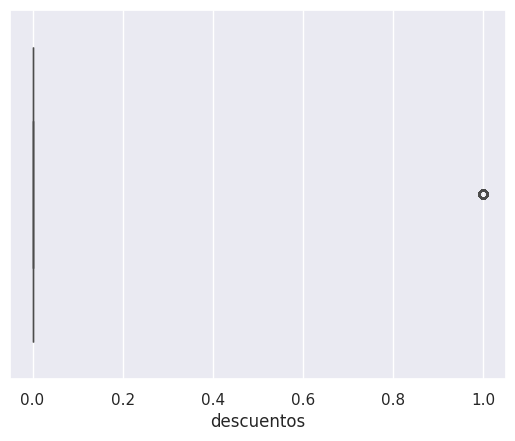

vel_conexion


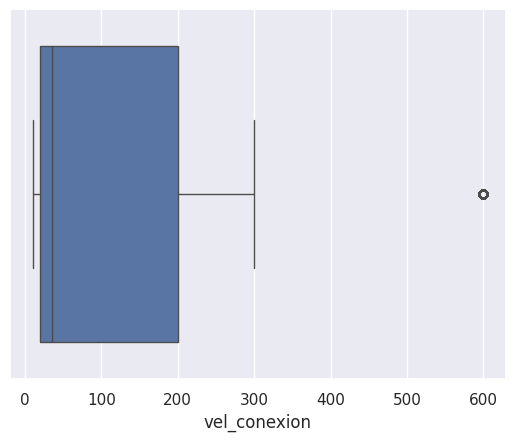

duracion


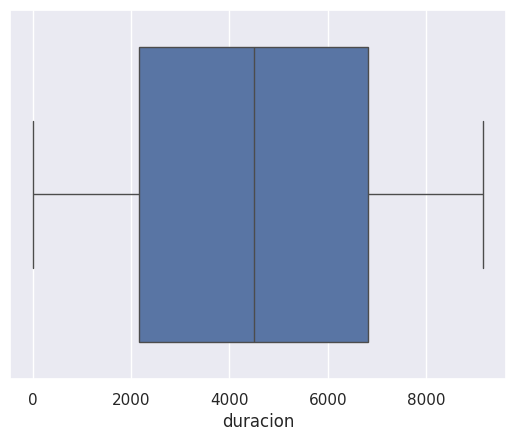

month


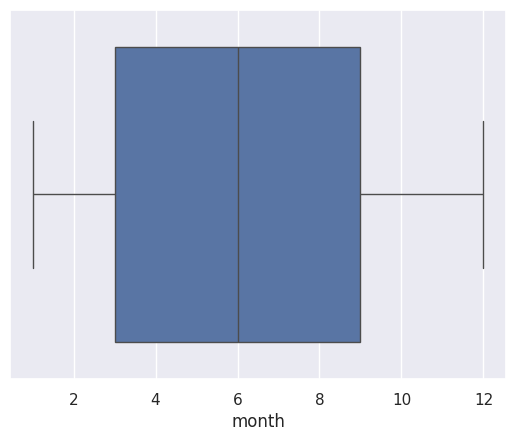

dia


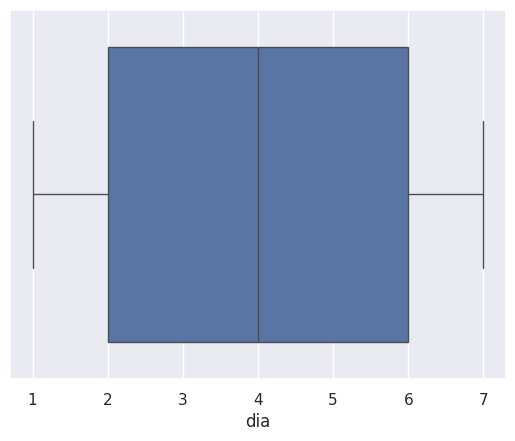

hora


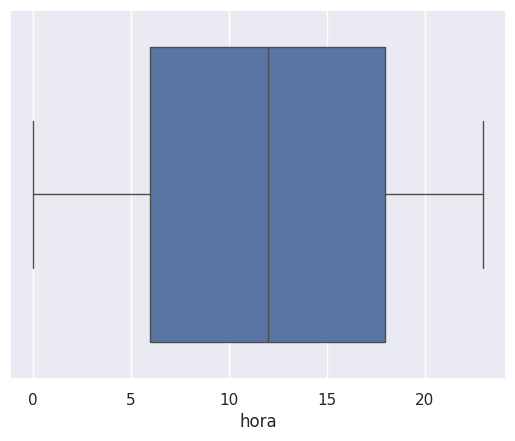

com_aut


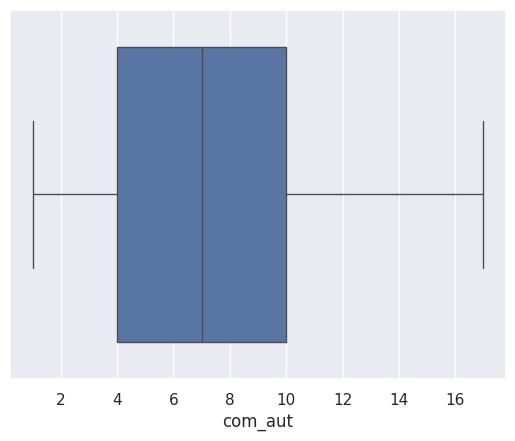

hora_bin


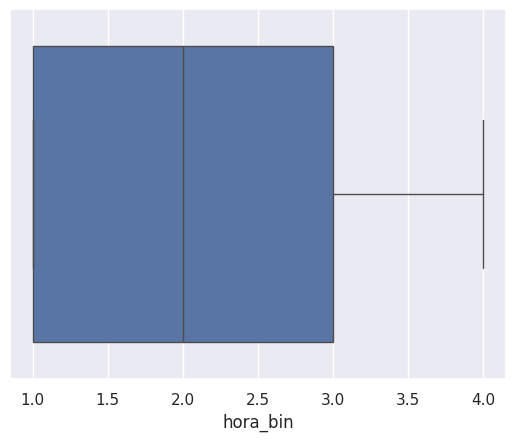

In [66]:
for i in list_correlacion:
    sns.boxplot(x=data[i])
    print(i)
    plt.show()


## Vemos posibles outliers en vel conexión y num_lineas. Vamos a comprobarlo con z_score

In [67]:
threshold = 3
z = np.abs(stats.zscore(data['vel_conexion']))
print(z)
print(np.where(z > 3))

[0.4820645  2.58795774 0.56579238 ... 0.64952026 0.4820645  0.62161096]
(array([], dtype=int64),)


/tmp/ipykernel_554/142945966.py:2: DeprecationWarning: Please import `zscore` from the `scipy.stats` namespace; the `scipy.stats.stats` namespace is deprecated and will be removed in SciPy 2.0.0.
  z = np.abs(stats.zscore(data['vel_conexion']))


In [68]:
threshold = 3
z = np.abs(stats.zscore(data['num_lineas']))
print(z)
print(np.where(z > 3))

## Hay 3 valores que están fuera del rango. Podemos eliminar esas filas

data.drop([2580,8657,36987], axis=0,inplace=True)

[1.32043529 0.51315751 0.40363889 ... 0.40363889 1.42995391 0.40363889]
(array([ 2580,  8657, 36987]),)


/tmp/ipykernel_554/503836170.py:2: DeprecationWarning: Please import `zscore` from the `scipy.stats` namespace; the `scipy.stats.stats` namespace is deprecated and will be removed in SciPy 2.0.0.
  z = np.abs(stats.zscore(data['num_lineas']))


In [69]:
### Todos los valores cumplen con el estandar

In [70]:
data.dtypes

,0
id,int64
edad,int64
facturacion,float64
num_lineas,int64
num_dt,float64
incidencia,int64
num_llamad_ent,int64
num_llamad_sal,int64
mb_datos,int64
seg_llamad_ent,int64


In [71]:
df_dic = pd.merge(data[data['mes']=='dic'], churn, on='id', how='left')

In [72]:
df_dic.drop('mes', axis=1, inplace=True)
df_dic.set_index('id', inplace=True)

In [73]:
df_dic

,edad,facturacion,num_lineas,num_dt,incidencia,num_llamad_ent,num_llamad_sal,mb_datos,seg_llamad_ent,seg_llamad_sal,...,dia,hora,hora_bin,conexion_ADSL,conexion_FIBRA,tv_tv-familiar,tv_tv-futbol,tv_tv-total,com_aut,churn
id,,,,,,,,,,,,,,,,,,,,,
1,63,216.028109,5,0.0,0,110,79,10897,12806,13751,...,5,8,2,False,True,False,True,False,1,0
2,84,255.830842,3,0.0,0,189,89,18657,6499,10862,...,2,3,1,False,True,False,True,False,2,0
3,66,135.768153,4,0.0,0,129,30,15511,17013,16743,...,4,13,3,True,False,False,True,False,3,0
4,69,255.658527,4,0.0,0,51,52,12670,3393,6771,...,6,10,2,False,True,True,False,False,4,0
5,30,22.302845,2,2.0,0,183,3,23756,18436,4485,...,5,2,1,True,False,False,True,False,5,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,65,173.741667,5,0.0,0,121,98,13403,6197,6853,...,2,0,1,True,False,True,False,False,17,0
99996,36,215.890326,3,0.0,0,98,13,5291,3684,1667,...,2,13,3,True,False,False,True,False,3,0
99997,68,285.890750,5,0.0,0,226,20,20002,572,5679,...,5,23,4,False,True,False,True,False,14,0


In [74]:
## Las variables más importantes del modelo son num_dt, incidencia, descuentos, financiacion, importe financiacion

In [75]:
corr = abs(df_dic.corr())
corr[['churn']].sort_values(by = 'churn',ascending = False)

,churn
churn,1.000000
num_dt,0.312762
edad,0.296714
incidencia,0.277354
tv_tv-futbol,0.152479
descuentos,0.141467
tv_tv-total,0.111124
tv_tv-familiar,0.079963
financiacion,0.074606
imp_financ,0.067633


In [76]:
def plot_target_vs_features(var, target, df):
    proporcion = pd.DataFrame()
    proporcion['%'] = df[target].groupby(df[var]).mean() * 100
    proporcion['Conteo'] = df[target].groupby(df[var]).count()
    proporcion = proporcion.round(3)
    proporcion_filtered = proporcion[(proporcion['%'] > 0) & (proporcion['Conteo'] > 10)]

    if len(proporcion_filtered) < 100 and len(proporcion_filtered) > 1:
        fig = px.bar(proporcion_filtered, x=proporcion_filtered.index, y='Conteo', title=f'Distribución de {var}', labels={'x': var, 'Conteo': 'Cantidad'}, template='plotly_white')
        fig.add_trace(go.Scatter(x=proporcion_filtered.index, y=proporcion_filtered['%'], mode='lines+markers', name='%', yaxis='y2', line=dict(color='green')))

        fig.update_layout(
            yaxis2=dict(title='%', overlaying='y', side='right')
        )
    elif len(proporcion_filtered) >= 100:
        df_filtered = df[[var, target]].dropna()
        df_filtered['bin'] = pd.qcut(df_filtered[var], q=20, duplicates='drop')
        bin_means = df_filtered.groupby('bin')[target].mean() * 100
        bin_counts = df_filtered.groupby('bin')[target].count()

        fig = go.Figure()
        fig.add_trace(go.Bar(x=bin_means.index.astype(str), y=bin_counts, name='Conteo', yaxis='y', marker_color='blue'))
        fig.add_trace(go.Scatter(x=bin_means.index.astype(str), y=bin_means, mode='lines+markers', name='%', yaxis='y2', line=dict(color='green')))

        fig.update_layout(
            title=f'Relación entre {var} y {target}',
            xaxis_title=f'Binned {var}',
            yaxis=dict(title='Conteo'),
            yaxis2=dict(title='%', overlaying='y', side='right'),
            template='plotly_white'
        )
    else:
        proporcion_filtered.reset_index(inplace=True)
        fig = px.scatter(proporcion_filtered, x=var, y='%', trendline='ols', title=f'Relación entre {var} y % Depósitos', template='plotly_white')

    fig.show()


In [77]:
for i in df_dic.columns:
    plot_target_vs_features (i, 'churn', df_dic)

/tmp/ipykernel_554/322798919.py:18: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_554/322798919.py:19: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



/tmp/ipykernel_554/322798919.py:18: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_554/322798919.py:19: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



/tmp/ipykernel_554/322798919.py:18: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_554/322798919.py:19: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



/tmp/ipykernel_554/322798919.py:18: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_554/322798919.py:19: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



/tmp/ipykernel_554/322798919.py:18: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_554/322798919.py:19: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



# Muestrear los datos, construyendo un dataset de train y test

   - Muestreo estratificado en función de la variable respuesta para que en los splits sus categorías estén bien representadas.
       - Split 80/20.

In [78]:
X_train, X_test, y_train, y_test = train_test_split (df_dic.drop('churn', axis=1),
                                                     df_dic.churn,
                                                     test_size = 0.2,
                                                     random_state = 0,
                                                     stratify = df_dic.churn)

# Construir un modelo analítico de clasificación que sea capaz de predecir cuando un cliente se fuga de la empresa

In [79]:
def saca_metricas(y1, y2):
    print('Matriz de Confusión')
    print(confusion_matrix(y1, y2))
    print('Accuracy:', accuracy_score(y1, y2))
    print('Precision:', precision_score(y1, y2))
    print('Recall:', recall_score(y1, y2))
    print('F1 Score:', f1_score(y1, y2))

    # Cálculo de la curva ROC y AUC
    false_positive_rate, recall, _ = roc_curve(y1, y2)
    roc_auc = auc(false_positive_rate, recall)
    print('AUC:', roc_auc)

    # Crear gráfico interactivo con Plotly
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=false_positive_rate, y=recall, mode='lines', name='Curva ROC', line=dict(color='blue')))
    fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode='lines', name='Línea base', line=dict(color='red', dash='dash')))

    fig.update_layout(
        title=f'Curva ROC (AUC = {roc_auc:.2f})',
        xaxis_title='False Positive Rate',
        yaxis_title='Recall',
        template='plotly_white'
    )

    fig.show()

In [80]:
mlflow.set_experiment("ejercicio_churn_ntic")

2026/03/12 07:27:34 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/03/12 07:27:34 INFO mlflow.store.db.utils: Updating database tables
2026/03/12 07:27:36 INFO mlflow.tracking.fluent: Experiment with name 'ejercicio_churn_ntic' does not exist. Creating a new experiment.


<Experiment: artifact_location='/content/mlruns/1', creation_time=1773300456834, experiment_id='1', last_update_time=1773300456834, lifecycle_stage='active', name='ejercicio_churn_ntic', tags={}, workspace='default'>

In [81]:
with mlflow.start_run(run_name='decission_tree'):

    # Modelo y predicciones:
    modelo = DecisionTreeClassifier(criterion="gini").fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    # Métricas:
    saca_metricas(y_test, y_pred)

    # predict_proba returns [prob_negative, prob_positive], so slice the output with [:, 1]
    accuracy = accuracy_score(y_test, y_pred)
    false_positive_rate, recall, thresholds = roc_curve(y_test, y_pred)
    roc_auc = auc(false_positive_rate, recall)

    # Use the area under the ROC curve as a metric.
    mlflow.log_metric('accuracy', accuracy)
    mlflow.log_metric('roc_auc', roc_auc)
    # log model
    mlflow.sklearn.log_model(modelo,'tree_ntic')
    # save model
    mlflow.sklearn.save_model(modelo, 'tree.pkl',
                              serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_PICKLE)

Matriz de Confusión
[[17013   663]
 [  552   865]]
Accuracy: 0.936364112501964
Precision: 0.5660994764397905
Recall: 0.6104446012702893
F1 Score: 0.5874363327674024
AUC: 0.7864680575937325


2026/03/12 07:27:38 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/12 07:27:38 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/12 07:27:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


In [82]:
with mlflow.start_run(run_name='random_forest'):

    modelo = RandomForestClassifier().fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    saca_metricas(y_test, y_pred)

    # predict_proba returns [prob_negative, prob_positive], so slice the output with [:, 1]
    accuracy = accuracy_score(y_test, y_pred)
    false_positive_rate, recall, thresholds = roc_curve(y_test, y_pred)
    roc_auc = auc(false_positive_rate, recall)

    # Use the area under the ROC curve as a metric.
    mlflow.log_metric('accuracy', accuracy)
    mlflow.log_metric('roc_auc', roc_auc)
    # log model
    mlflow.sklearn.log_model(modelo,'rf_ntic')
    # save model
    mlflow.sklearn.save_model(modelo, 'rf.pkl',
                              serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_PICKLE)

Matriz de Confusión
[[17602    74]
 [  606   811]]
Accuracy: 0.964384853087519
Precision: 0.9163841807909604
Recall: 0.5723359209597741
F1 Score: 0.7046046915725456
AUC: 0.7840747267165922


2026/03/12 07:28:12 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/12 07:28:12 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/12 07:28:17 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


In [83]:
with mlflow.start_run(run_name='linear'):

    modelo = LinearSVC(penalty='l1', dual= False).fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    saca_metricas(y_test, y_pred)

    # predict_proba returns [prob_negative, prob_positive], so slice the output with [:, 1]
    accuracy = accuracy_score(y_test, y_pred)
    false_positive_rate, recall, thresholds = roc_curve(y_test, y_pred)
    roc_auc = auc(false_positive_rate, recall)

    # Use the area under the ROC curve as a metric.
    mlflow.log_metric('accuracy', accuracy)
    mlflow.log_metric('roc_auc', roc_auc)
    # log model
    mlflow.sklearn.log_model(modelo,'linear_ntic')
    # save model
    mlflow.sklearn.save_model(modelo, 'linear.pkl',
                              serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_PICKLE)

Matriz de Confusión
[[17570   106]
 [  805   612]]
Accuracy: 0.952286178180485
Precision: 0.8523676880222841
Recall: 0.4318983768525053
F1 Score: 0.5733021077283372
AUC: 0.7129507724950466


/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning:

Liblinear failed to converge, increase the number of iterations.



2026/03/12 07:28:38 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/12 07:28:39 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/12 07:28:43 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


In [84]:
with mlflow.start_run(run_name='logistic'):

    modelo = LogisticRegression(max_iter=10000).fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    saca_metricas(y_test, y_pred)

    # predict_proba returns [prob_negative, prob_positive], so slice the output with [:, 1]
    accuracy = accuracy_score(y_test, y_pred)
    false_positive_rate, recall, thresholds = roc_curve(y_test, y_pred)
    roc_auc = auc(false_positive_rate, recall)

    # Use the area under the ROC curve as a metric.
    mlflow.log_metric('accuracy', accuracy)
    mlflow.log_metric('roc_auc', roc_auc)
    # log model
    mlflow.sklearn.log_model(modelo,'logistc_ntic')
    # save model
    mlflow.sklearn.save_model(modelo, 'logistic.pkl',
                              serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_PICKLE)

Matriz de Confusión
[[17592    84]
 [  850   567]]
Accuracy: 0.9510815482113864
Precision: 0.8709677419354839
Recall: 0.40014114326040934
F1 Score: 0.5483558994197292
AUC: 0.6976944684394376


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning:

lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression



2026/03/12 07:32:30 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/12 07:32:30 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/12 07:32:35 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


In [85]:
with mlflow.start_run(run_name='gaussiano'):

    modelo = GaussianNB().fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    saca_metricas(y_test, y_pred)

    # predict_proba returns [prob_negative, prob_positive], so slice the output with [:, 1]
    accuracy = accuracy_score(y_test, y_pred)
    false_positive_rate, recall, thresholds = roc_curve(y_test, y_pred)
    roc_auc = auc(false_positive_rate, recall)

    # Use the area under the ROC curve as a metric.
    mlflow.log_metric('accuracy', accuracy)
    mlflow.log_metric('roc_auc', roc_auc)
    # log model
    mlflow.sklearn.log_model(modelo,'gaussiano_ntic')
    # save model
    mlflow.sklearn.save_model(modelo, 'gaussiano.pkl',
                              serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_PICKLE)

Matriz de Confusión
[[14749  2927]
 [   62  1355]]
Accuracy: 0.8434504792332268
Precision: 0.31644091546006536
Recall: 0.9562455892731122
F1 Score: 0.4755220214072644
AUC: 0.89532691321542


2026/03/12 07:32:40 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/12 07:32:40 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/12 07:32:45 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


In [86]:
# Modelo final

modelo = RandomForestClassifier().fit(X_train, y_train)
y_pred = modelo.predict(X_test)

In [87]:
# Validación cruzada

cv = cross_val_score(
    modelo,
    X_train,
    y_train,
    scoring = "roc_auc",
    cv = 5
)
print(cv)
print("CV ROC:", cv.mean(), np.std(cv))

[0.95913216 0.96614393 0.96345034 0.96305639 0.96348018]
CV ROC: 0.9630525994776349 0.002247985381958685


## MEJORA DE MODELOS

In [88]:
imp = {}
for i in range(len(X_train.columns)):
    imp[X_train.columns[i]] = [modelo.feature_importances_[i]]
pd.DataFrame.from_dict(imp, orient="index", columns=["Importance"]).sort_values("Importance", ascending=False).head(20).style.background_gradient()

,Importance
edad,0.171147
num_dt,0.150130
incidencia,0.099537
descuentos,0.058306
vel_conexion,0.054692
facturacion,0.045218
seg_llamad_ent,0.042979
duracion,0.042624
mb_datos,0.042111
seg_llamad_sal,0.041472


In [89]:
## Tuning hiperparámetros

In [90]:
grid_param = {
    'n_estimators': [100,300,500],
    'criterion': ['gini', 'entropy'],
    'max_depth': [16,20,22,24],
    'max_features': ['auto', 'sqrt'],

}

In [91]:
stratified_kfold = StratifiedKFold(n_splits=5,
                                       shuffle=True,
                                       random_state=11)

In [92]:
model_grid = GridSearchCV(estimator=modelo,
                     param_grid=grid_param,
                     scoring='recall',
                     cv=stratified_kfold,
                     n_jobs=-1)

In [93]:
#model_grid.fit(X_train, y_train)

In [94]:
#model_grid.best_params_

In [95]:
#model_grid.best_score_

In [96]:
modelo = RandomForestClassifier(criterion = 'entropy', n_estimators= 100, max_depth = 22, max_features= 'sqrt').fit(X_train, y_train)
y_pred = modelo.predict(X_test)
saca_metricas(y_test, y_pred)

Matriz de Confusión
[[17601    75]
 [  606   811]]
Accuracy: 0.9643324778714712
Precision: 0.9153498871331829
Recall: 0.5723359209597741
F1 Score: 0.7042987407729049
AUC: 0.7840464397738449


In [97]:
print("Before OverSampling, counts of label '1': {}".format(sum(y_train==1)))
print("Before OverSampling, counts of label '0': {}".format(sum(y_train==0)))

sm = SMOTE(sampling_strategy=0.6, random_state=2)
X_train_res, y_train_res = sm.fit_resample(X_train,y_train.ravel())

print('After OverSampling, the shape of train_X: {}'.format(X_train_res.shape))
print('After OverSampling, the shape of train_y: {}'.format(y_train_res.shape))

print("After OverSampling, counts of label '1': {}".format(sum(y_train_res==1)))
print("After OverSampling, counts of label '0': {}".format(sum(y_train_res==0)))

Before OverSampling, counts of label '1': 5670
Before OverSampling, counts of label '0': 70700


/tmp/ipykernel_554/3124199294.py:5: FutureWarning:

Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.



After OverSampling, the shape of train_X: (113120, 25)
After OverSampling, the shape of train_y: (113120,)
After OverSampling, counts of label '1': 42420
After OverSampling, counts of label '0': 70700


In [98]:
modelo = RandomForestClassifier(criterion = 'entropy', n_estimators= 100, max_depth = 22, max_features= 'sqrt')
modelo.fit(X_train_res, y_train_res)
y_pred = modelo.predict(X_test)
saca_metricas(y_test, y_pred)

Matriz de Confusión
[[17291   385]
 [  514   903]]
Accuracy: 0.9529146807730582
Precision: 0.7010869565217391
Recall: 0.6372618207480593
F1 Score: 0.6676524953789279
AUC: 0.8077404374163468


In [99]:
def plot_feature_importance(model, X_train):
    feat_importances = pd.DataFrame(model.feature_importances_, index=X_train.columns, columns=["Importance"])
    feat_importances.sort_values(by='Importance', ascending=False, inplace=True)

    fig = px.bar(feat_importances, x=feat_importances.index, y='Importance', title='Feature Importances', labels={'x': 'Features', 'Importance': 'Importance'}, template='plotly_white')
    fig.show()

    return feat_importances

In [100]:
feature_importances = plot_feature_importance(modelo, X_train_res)

## Finalizamos/entregables

In [101]:
pkl_filename = "modelo1.pkl"
with open(pkl_filename, 'wb') as file:
    pickle.dump(modelo, file)

# Load from file
with open(pkl_filename, 'rb') as file:
    pickle_model = pickle.load(file)

In [102]:
## Predicción de febrero

In [103]:
df_ene = data[data['mes']=='en']

In [104]:
df_ene.drop('mes', axis=1, inplace=True)
df_ene.set_index('id', inplace=True)

/tmp/ipykernel_554/363083108.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [105]:
df_ene['score'] = modelo.predict_proba(df_ene)[:,1]

/tmp/ipykernel_554/4036784999.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [106]:
df_ene.sort_values('score', ascending=False).to_csv('reporte_final.csv')

In [107]:
modelo.predict_proba(df_ene.drop('score', axis=1))[:,1]

array([0.        , 0.        , 0.        , ..., 0.52054207, 0.        ,
       0.0018    ])

In [108]:
df_ene.sort_values('score', ascending=False)[0:1000]

,edad,facturacion,num_lineas,num_dt,incidencia,num_llamad_ent,num_llamad_sal,mb_datos,seg_llamad_ent,seg_llamad_sal,...,dia,hora,hora_bin,conexion_ADSL,conexion_FIBRA,tv_tv-familiar,tv_tv-futbol,tv_tv-total,com_aut,score
id,,,,,,,,,,,,,,,,,,,,,
58410,39,72.515091,4,3.0,0,53,13,2573,10243,9304,...,6,3,1,True,False,False,True,False,10,0.993352
85746,18,75.137762,3,1.0,0,65,57,1427,15052,7178,...,6,2,1,True,False,False,True,False,6,0.981778
95054,21,64.803807,2,2.0,0,215,82,7088,11182,1035,...,2,17,3,True,False,False,True,False,10,0.976654
25047,18,52.622263,4,4.0,0,136,75,9090,15844,15971,...,4,18,3,True,False,False,True,False,2,0.972553
89181,27,149.228437,2,4.0,0,95,58,12163,707,10173,...,1,1,1,False,True,False,True,False,12,0.971784
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43355,18,290.163221,3,0.0,0,196,39,6146,14788,10872,...,5,10,2,True,False,False,True,False,12,0.592926
17353,31,141.251356,3,0.0,0,55,72,8892,16242,17700,...,4,6,1,True,False,False,True,False,2,0.592797
34100,30,346.004543,3,0.0,0,17,56,749,19504,2320,...,2,17,3,True,False,False,True,False,5,0.592520
